# Drive Mounting & Dataset Verification

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

drive_folder = "/content/drive/MyDrive/Plant_Disease_Project"
for file in os.listdir(drive_folder):
    print(file)

zip_path = "/content/drive/MyDrive/Plant_Disease_Project/PLANT DISEASE PROJECT .zip"
print("File exists:", os.path.exists(zip_path))
print("File size:", round(os.path.getsize(zip_path) / (1024**3), 2), "GB")

Mounted at /content/drive
PLANT DISEASE PROJECT .zip
cloudflared
tomato_svm_model.joblib
app.py
requirements.txt
README.md
File exists: True
File size: 2.7 GB


# ZIP Inspection & Extraction

In [ ]:
import zipfile
from tqdm import tqdm

with zipfile.ZipFile(zip_path, 'r') as z:
    files = z.infolist()
    total_size = sum(f.file_size for f in files)
    print("Total files:", len(files))
    print("Uncompressed size:", round(total_size / (1024**3), 2), "GB")

extract_path = "/content/tomato_dataset"
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    tomato_files = [
        f for f in z.namelist()
        if len(f.split("/")) >= 5
        and f.split("/")[2] in ["train", "valid"]
        and f.split("/")[3].startswith("Tomato___")
        and f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    print("Images to extract:", len(tomato_files))

    for file in tqdm(tomato_files):
        parts = file.split("/")
        split = parts[2]
        class_name = parts[3]
        filename = parts[-1]

        destination = os.path.join(extract_path, split, class_name, filename)
        os.makedirs(os.path.dirname(destination), exist_ok=True)

        with z.open(file) as source, open(destination, "wb") as target:
            target.write(source.read())

print("Extraction completed!")

Total files: 175767
Uncompressed size: 2.66 GB
Images to extract: 45860


100%|██████████| 45860/45860 [00:37<00:00, 1207.43it/s]

Extraction completed!


# Dataset Inspection & Exploration

In [ ]:
TRAIN_DIR = "/content/tomato_dataset/train"
VALID_DIR = "/content/tomato_dataset/valid"

for folder_name, folder_path in [("TRAIN", TRAIN_DIR), ("VALIDATION", VALID_DIR)]:
    print(f"\n{folder_name} DATASET")
    print("-" * 50)
    total = 0
    for class_name in sorted(os.listdir(folder_path)):
        class_path = os.path.join(folder_path, class_name)
        if os.path.isdir(class_path):
            count = len([f for f in os.listdir(class_path) if f.lower().endswith((".jpg", ".jpeg", ".png"))])
            total += count
            print(f"{class_name}: {count}")
    print("Total images:", total)


TRAIN DATASET
--------------------------------------------------
Tomato___Bacterial_spot: 1702
Tomato___Early_blight: 1920
Tomato___Late_blight: 1851
Tomato___Leaf_Mold: 1882
Tomato___Septoria_leaf_spot: 1745
Tomato___Spider_mites Two-spotted_spider_mite: 1741
Tomato___Target_Spot: 1827
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 1961
Tomato___Tomato_mosaic_virus: 1790
Tomato___healthy: 1926
Total images: 18345

VALIDATION DATASET
--------------------------------------------------
Tomato___Bacterial_spot: 425
Tomato___Early_blight: 480
Tomato___Late_blight: 463
Tomato___Leaf_Mold: 470
Tomato___Septoria_leaf_spot: 436
Tomato___Spider_mites Two-spotted_spider_mite: 435
Tomato___Target_Spot: 457
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 490
Tomato___Tomato_mosaic_virus: 448
Tomato___healthy: 481
Total images: 4585


# Preprocessing & HOG Feature Extraction

In [ ]:
import numpy as np
from PIL import Image
from skimage.feature import hog

def extract_features(dataset_path):
    features = []
    labels = []
    for class_name in sorted(os.listdir(dataset_path)):
        class_path = os.path.join(dataset_path, class_name)
        if os.path.isdir(class_path):
            for file in tqdm(os.listdir(class_path), desc=class_name):
                if file.lower().endswith((".jpg", ".jpeg", ".png")):
                    image_path = os.path.join(class_path, file)
                    image = Image.open(image_path).convert("L")
                    image = image.resize((64, 64))
                    image_array = np.array(image)

                    hog_features = hog(
                        image_array,
                        orientations=9,
                        pixels_per_cell=(8, 8),
                        cells_per_block=(2, 2),
                        feature_vector=True
                    )
                    features.append(hog_features)
                    labels.append(class_name)
    return np.array(features, dtype=np.float32), np.array(labels)

X_train, y_train = extract_features(TRAIN_DIR)
X_valid, y_valid = extract_features(VALID_DIR)

Tomato___healthy: 100%|██████████| 481/481 [00:01<00:00, 443.12it/s]


# Encoding, Scaling & Final SVM Training

Final SVM Model Training Completed!
Final Validation Accuracy: 0.5683751363140677

Classification Report:

                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot       0.63      0.73      0.68       425
                        Tomato___Early_blight       0.44      0.38      0.41       480
                         Tomato___Late_blight       0.51      0.50      0.51       463
                           Tomato___Leaf_Mold       0.54      0.54      0.54       470
                  Tomato___Septoria_leaf_spot       0.40      0.33      0.36       436
Tomato___Spider_mites Two-spotted_spider_mite       0.61      0.65      0.63       435
                         Tomato___Target_Spot       0.47      0.39      0.43       457
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.64      0.71      0.67       490
                 Tomato___Tomato_mosaic_virus       0.70      0.77      0.74       448
                      

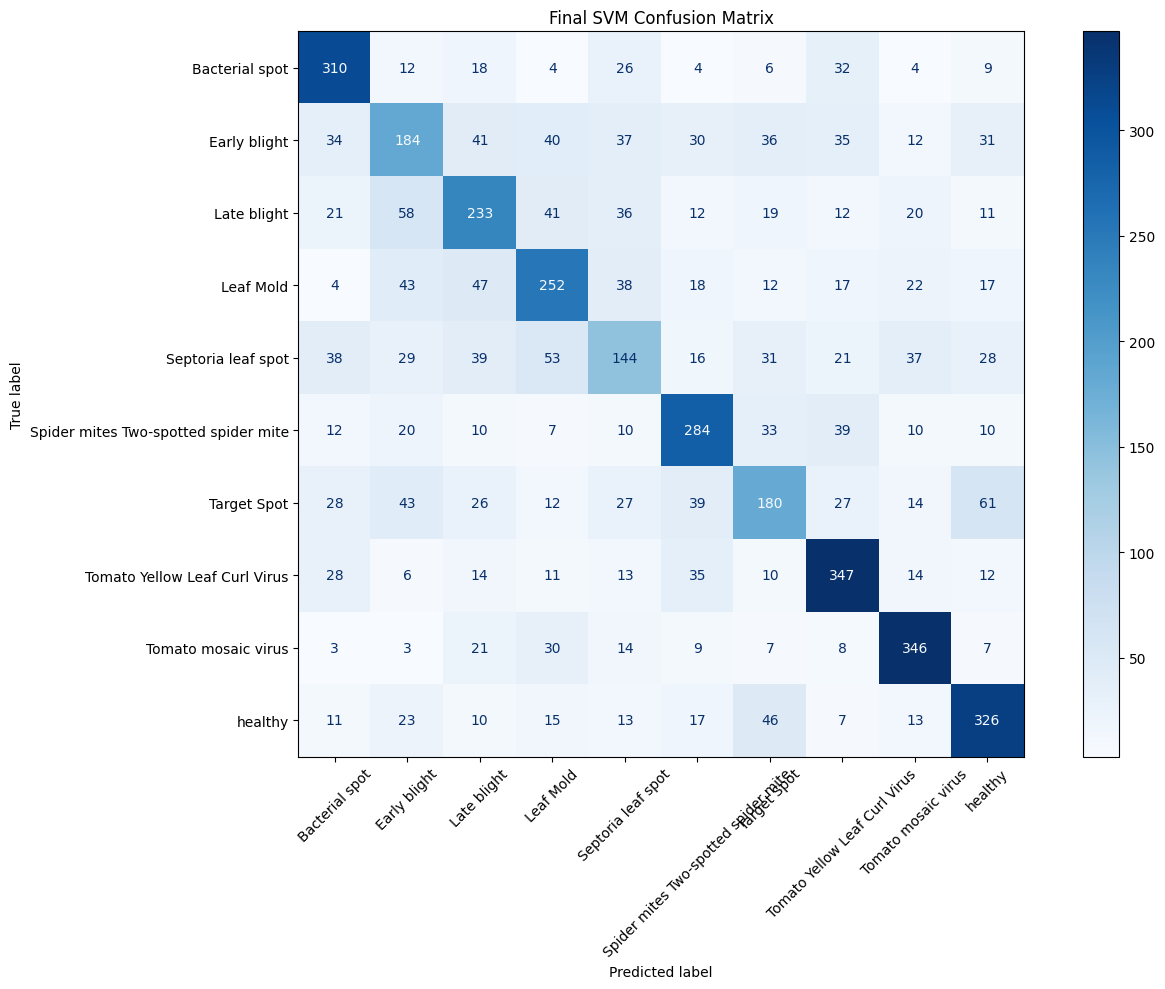

In [ ]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_valid_encoded = le.transform(y_valid)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

# Final Model Training with Best C Parameter (0.01)
best_svm_model = LinearSVC(C=0.01, random_state=42, max_iter=5000, dual="auto")
best_svm_model.fit(X_train_scaled, y_train_encoded)
print("Final SVM Model Training Completed!")

y_pred_final = best_svm_model.predict(X_valid_scaled)
final_accuracy = accuracy_score(y_valid_encoded, y_pred_final)
print("Final Validation Accuracy:", final_accuracy)
print("\nClassification Report:\n")
print(classification_report(y_valid_encoded, y_pred_final, target_names=le.classes_))

# Final Confusion Matrix
cm = confusion_matrix(y_valid_encoded, y_pred_final)
class_names = [name.replace("Tomato___", "").replace("_", " ") for name in le.classes_]
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(14, 10))
disp.plot(cmap="Blues", xticks_rotation=45, values_format="d", ax=ax)
plt.title("Final SVM Confusion Matrix")
plt.tight_layout()
plt.show()

# Model Saving

In [ ]:
import joblib

model_bundle = {
    "scaler": scaler,
    "model": best_svm_model,
    "label_encoder": le,
    "image_size": (64, 64),
    "hog_params": {
        "orientations": 9,
        "pixels_per_cell": (8, 8),
        "cells_per_block": (2, 2)
    }
}

save_path = "/content/drive/MyDrive/Plant_Disease_Project/tomato_svm_model.joblib"
joblib.dump(model_bundle, save_path)
print("Model saved successfully at:", save_path)

Model saved successfully at: /content/drive/MyDrive/Plant_Disease_Project/tomato_svm_model.joblib


# Streamlit App & Repository Generation

In [ ]:

import os
import shutil

source = "/content/drive/MyDrive/Plant_Disease_Project"
destination = "/content/Plant_Disease_GitHub"

os.makedirs(destination, exist_ok=True)

files_to_copy = [
    "app.py",
    "requirements.txt",
    "README.md",
    "tomato_svm_model.joblib"
]

for file in files_to_copy:
    shutil.copy2(
        os.path.join(source, file),
        os.path.join(destination, file)
    )

print("GitHub project folder created!")
print(os.listdir(destination))

GitHub project folder created!
['requirements.txt', 'README.md', 'app.py', 'tomato_svm_model.joblib']


In [ ]:


### Cell 8: GitHub Staging & Path Adjustment
import shutil

source = "/content/drive/MyDrive/Plant_Disease_Project"
destination = "/content/Plant_Disease_GitHub"
os.makedirs(destination, exist_ok=True)

files_to_copy = ["app.py", "requirements.txt", "README.md", "tomato_svm_model.joblib"]
for file in files_to_copy:
    shutil.copy2(os.path.join(source, file), os.path.join(destination, file))

app_path = "/content/Plant_Disease_GitHub/app.py"
with open(app_path, "r") as file:
    code = file.read()

code = code.replace(
    'MODEL_PATH = "/content/drive/MyDrive/Plant_Disease_Project/tomato_svm_model.joblib"',
    'MODEL_PATH = "tomato_svm_model.joblib"'
)

with open(app_path, "w") as file:
    file.write(code)

print("GitHub folder and model path updated successfully!")

GitHub folder and model path updated successfully!
